In [1]:
from UMAP_utils import *

# Parameters

In [2]:
CONCATENATE_DATA = True
SAVE_CONCATENATED_DATA = True
CLEAN_DATA = True

features = [
    "n_foci",
    "area",
    "equivalent_diameter_area",
    "eccentricity",
    "perimeter",
    "solidity",
    "mean_intensity",
    "max_intensity",
    "min_intensity",
]

# Import data and cleaning

In [3]:
# Root directory where the data is stored
root_dir = "/mnt/c/Users/helen/Desktop/data"

df = pd.read_csv(f"{root_dir}/CSV_FILES/concatenated_data_gmm4.csv")

df.shape

(278, 11)

In [ ]:
# Root directory where the data is stored
root_dir = "/mnt/c/Users/helen/Desktop/data"

# Path to the aggregated data files for each condition
data = [
        {'name': 'WT', 'path': f"{root_dir}/WT/gmm4/aggregated_data.csv"},
        {'name': 'WT, NC', 'path': f"{root_dir}/WT_NC/gmm4/aggregated_data.csv"},
        {'name': 'WT, Apt.3', 'path': f"{root_dir}/WT_Apt3/gmm4/aggregated_data.csv"},
        {'name': 'MGS3', 'path': f"{root_dir}/MGS3/gmm4/aggregated_data.csv"},
        {'name': 'MGS3, NC', 'path': f"{root_dir}/MGS3_NC/gmm4/aggregated_data.csv"},
        {'name': 'MGS3, Apt.3', 'path': f"{root_dir}/MGS3_Apt3/gmm4/aggregated_data.csv"},
    ]

# Add the labels for each condition to the data list
labels = [df['name'] for df in data]
print(f"Sample labels: {labels}")

# Load the dataframes from the specified paths
dfs = []
for item in data:
        p = item["path"]
        df = pd.read_csv(p)
        dfs.append(df)

# Print the number of dataframes loaded
N_files = len(dfs)
print(f"Loaded {N_files} dataframes.")

if CONCATENATE_DATA:
    df = pd.concat(
        [df.assign(sample=sample) for df, sample in zip(dfs, labels)],
        ignore_index=True
    )

    print(f"Concatenated dataframe shape: {df.shape}")

if CLEAN_DATA:
    #df = df.iloc[:, 2:]
    df.columns = df.columns.str.strip().str.lower()
    df.iloc[:, 1:9] = df.iloc[:, 1:9].apply(pd.to_numeric, errors="coerce")
    df = df.dropna()
    print(f"Cleaned dataframe shape: {df.shape}")
    
if SAVE_CONCATENATED_DATA:
    concatenated_path = f"{root_dir}/concatenated_data.csv"
    df.to_csv(concatenated_path, index=False)
    print(f"Concatenated dataframe saved to: {concatenated_path}")

# UMAP for all data

In [4]:
umap_df = calculate_umap(df, features, n_neighbors=20)

### UMAP Plot

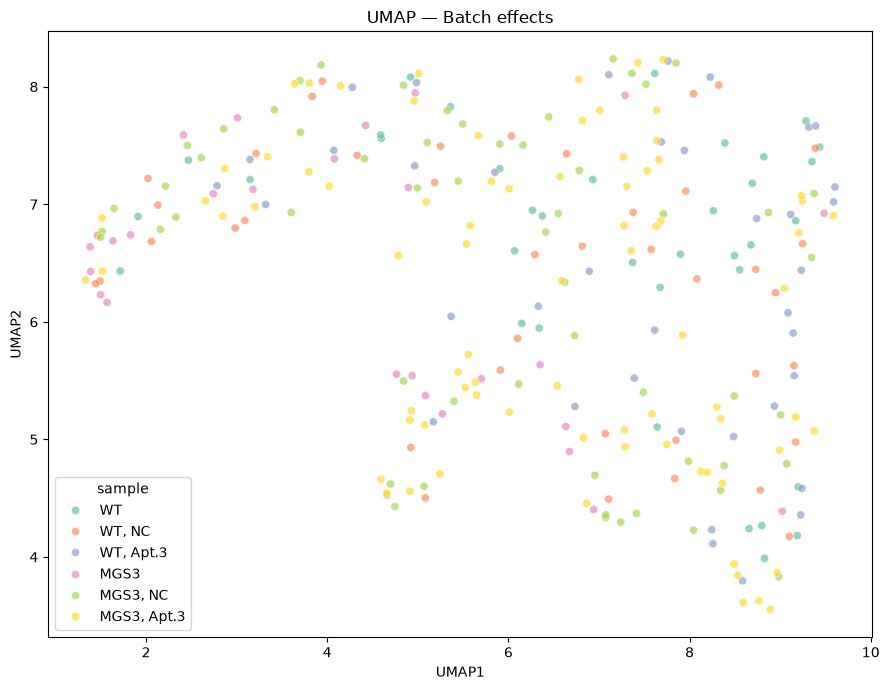

In [5]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="sample",
    palette="Set2",
    alpha=0.7,
    s=35
)

plt.title("UMAP — Batch effects")
plt.tight_layout()
plt.show()

### PERANOVA and PERMDISP for all data

In [6]:
results = run_permanova_permdisp(
    df=umap_df,
    features=features,
    variable="sample"
)

     Test        F  p_value       R2   n  groups
PERMANOVA 2.873106   0.0005 0.050165 278       6
 PERMDISP 1.832266   0.1055      NaN 278       6


###  Data subset and PERMANOVA recalculation

### Optional: Exlude some replicates: df_clean

In [ ]:
# Choose experiment to exclude
#exclude_experiment = "020226"  # Change to your experiment name

# Remove selected experiment
#df_clean = df[
#    df["experiment"] != exclude_experiment
#].dropna(
#    subset=features + ["experiment"]
#).copy()

#print("Remaining experiments:")
#print(df_clean["experiment"].value_counts())

### Vary n neighbours for UMAP

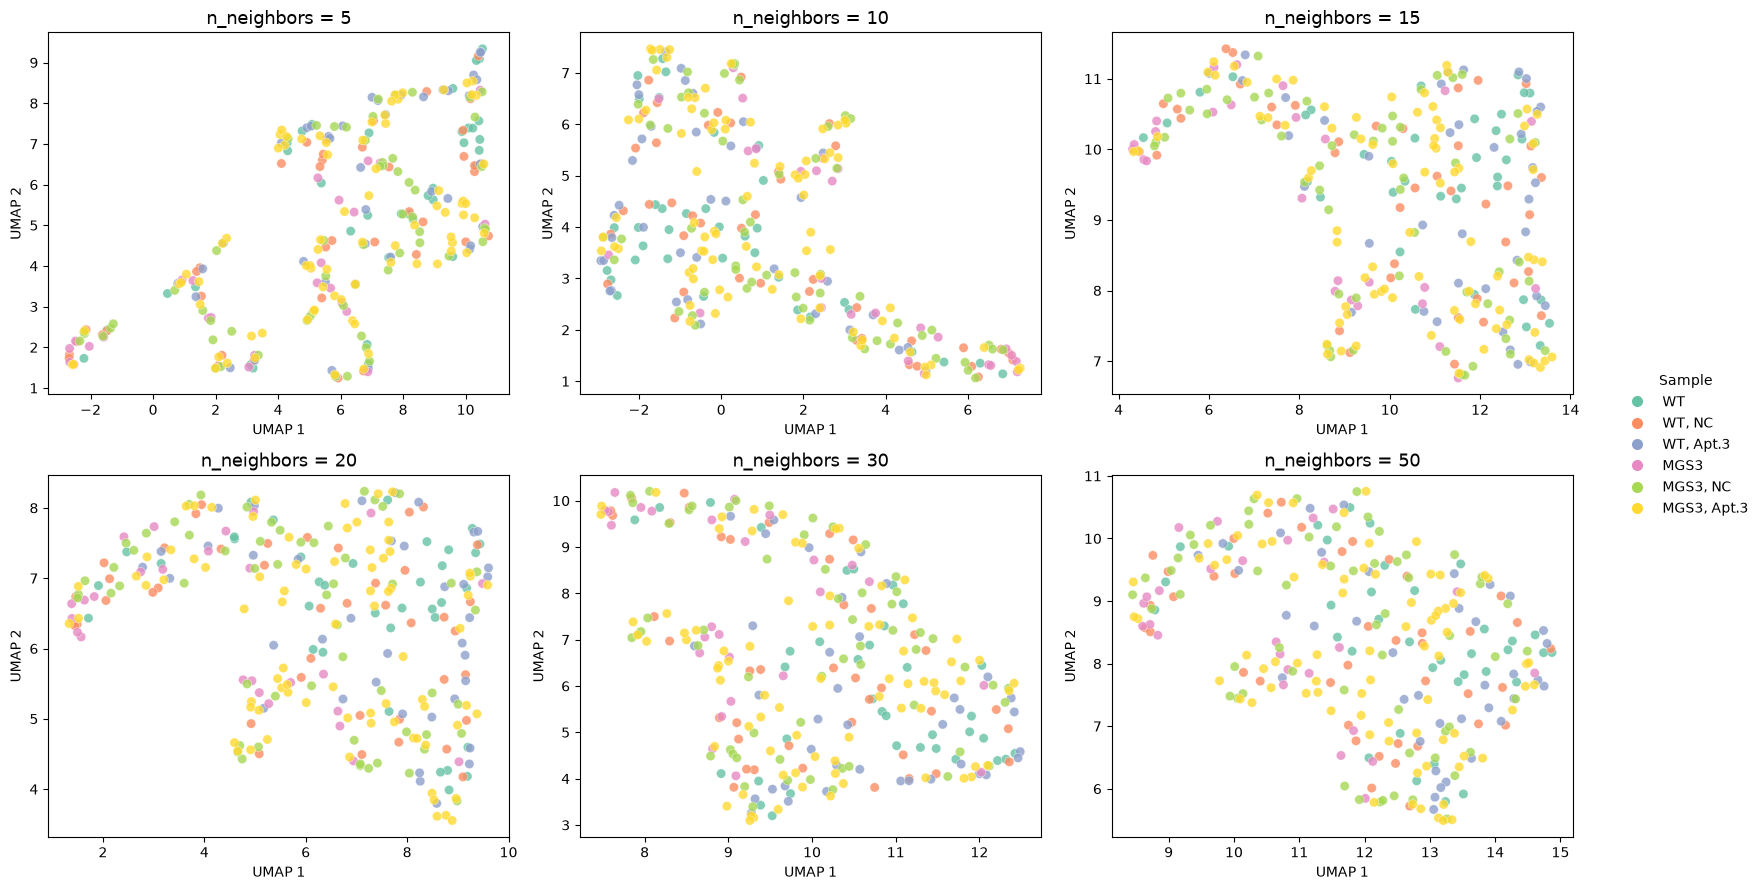

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

neighbors = [5, 10, 15, 20, 30, 50]

# Consistent colors for samples
samples = df["sample"].unique()

palette = dict(zip(
    samples,
    sns.color_palette("Set2", len(samples))
))

for ax, n in zip(axes.flat, neighbors):
    umap_df = calculate_umap(df=df, features=features, n_neighbors=n)

    sns.scatterplot(
        x=umap_df["UMAP1"],
        y=umap_df["UMAP2"],
        hue=umap_df["sample"].to_numpy(),
        hue_order=samples,
        palette=palette,
        s=45,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.3,
        legend=False,
        ax=ax
    )

    ax.set_title(f"n_neighbors = {n}", fontsize=13)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")

# Create shared legend
handles = [
    Line2D(
        [0], [0],
        marker="o",
        linestyle="",
        label=sample,
        markerfacecolor=palette[sample],
        markeredgecolor="white",
        markersize=9
    )
    for sample in samples
]

fig.legend(
    handles=handles,
    title="Sample",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    frameon=False
)

plt.tight_layout()
plt.show()

### Chose the particular UMAP settings for the following analysis

In [8]:
umap_df = calculate_umap(
    df,
    features,
    n_neighbors=20
)

In [ ]:
#score = trustworthiness(
#    X_scaled,
#    X_umap,
#    n_neighbors=n_neighbors
#)

#print(f"UMAP trustworthiness: {score:.4f}")

#### Plot

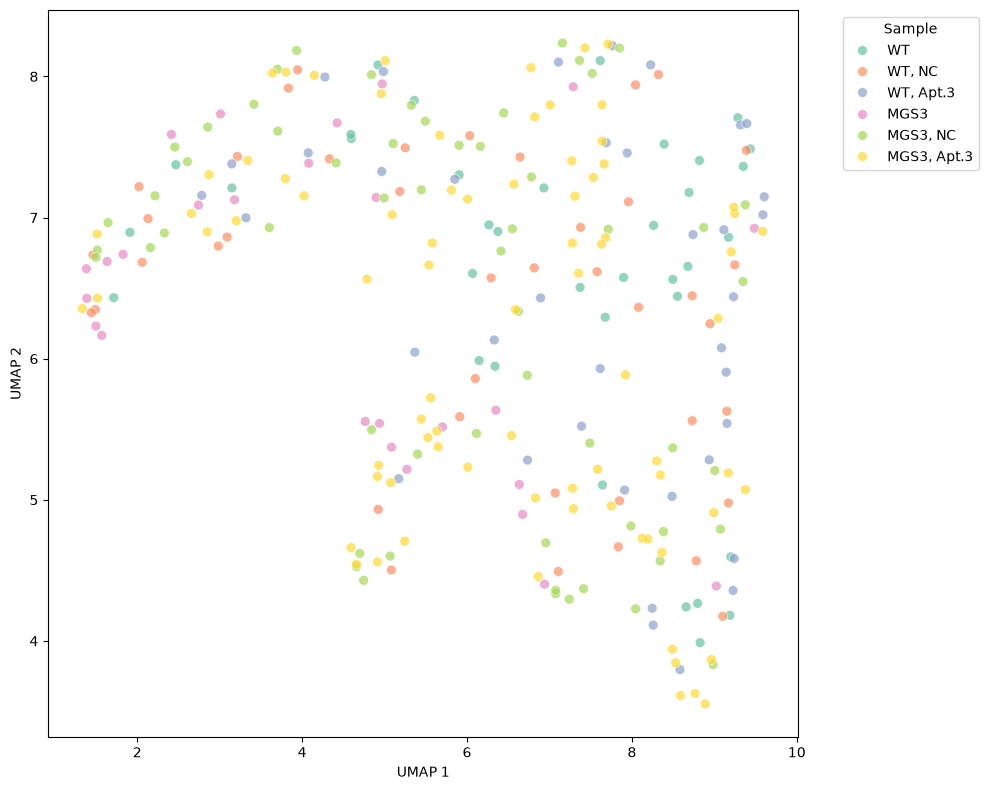

In [9]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="sample",
    palette="Set2",
    s=50,
    alpha=0.7
)

plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
#plt.title(f"UMAP (n_neighbors={n_neighbors})")

plt.legend(
    title="Sample",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### UMAP Loadings

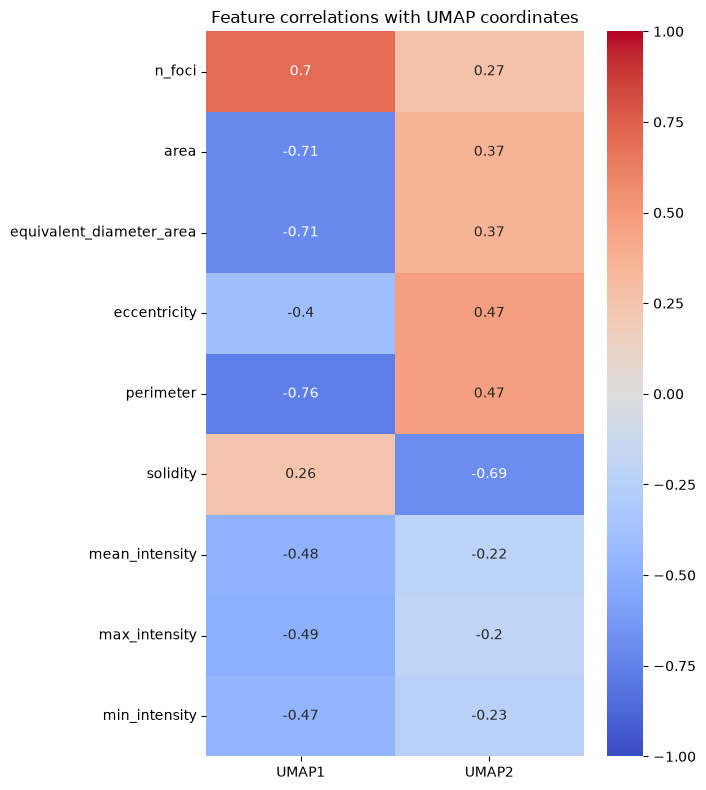

In [10]:
# Spearman correlations
correlations =  umap_df[features + ["UMAP1", "UMAP2"]].corr(method="spearman")

# Select feature correlations with UMAP axes
umap_corr = correlations.loc[
    features, ["UMAP1", "UMAP2"]
]

# Plot heatmap
plt.figure(figsize=(7, 8))

sns.heatmap(
    umap_corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Feature correlations with UMAP coordinates")
plt.tight_layout()
plt.show()

### Visualize each sample separately

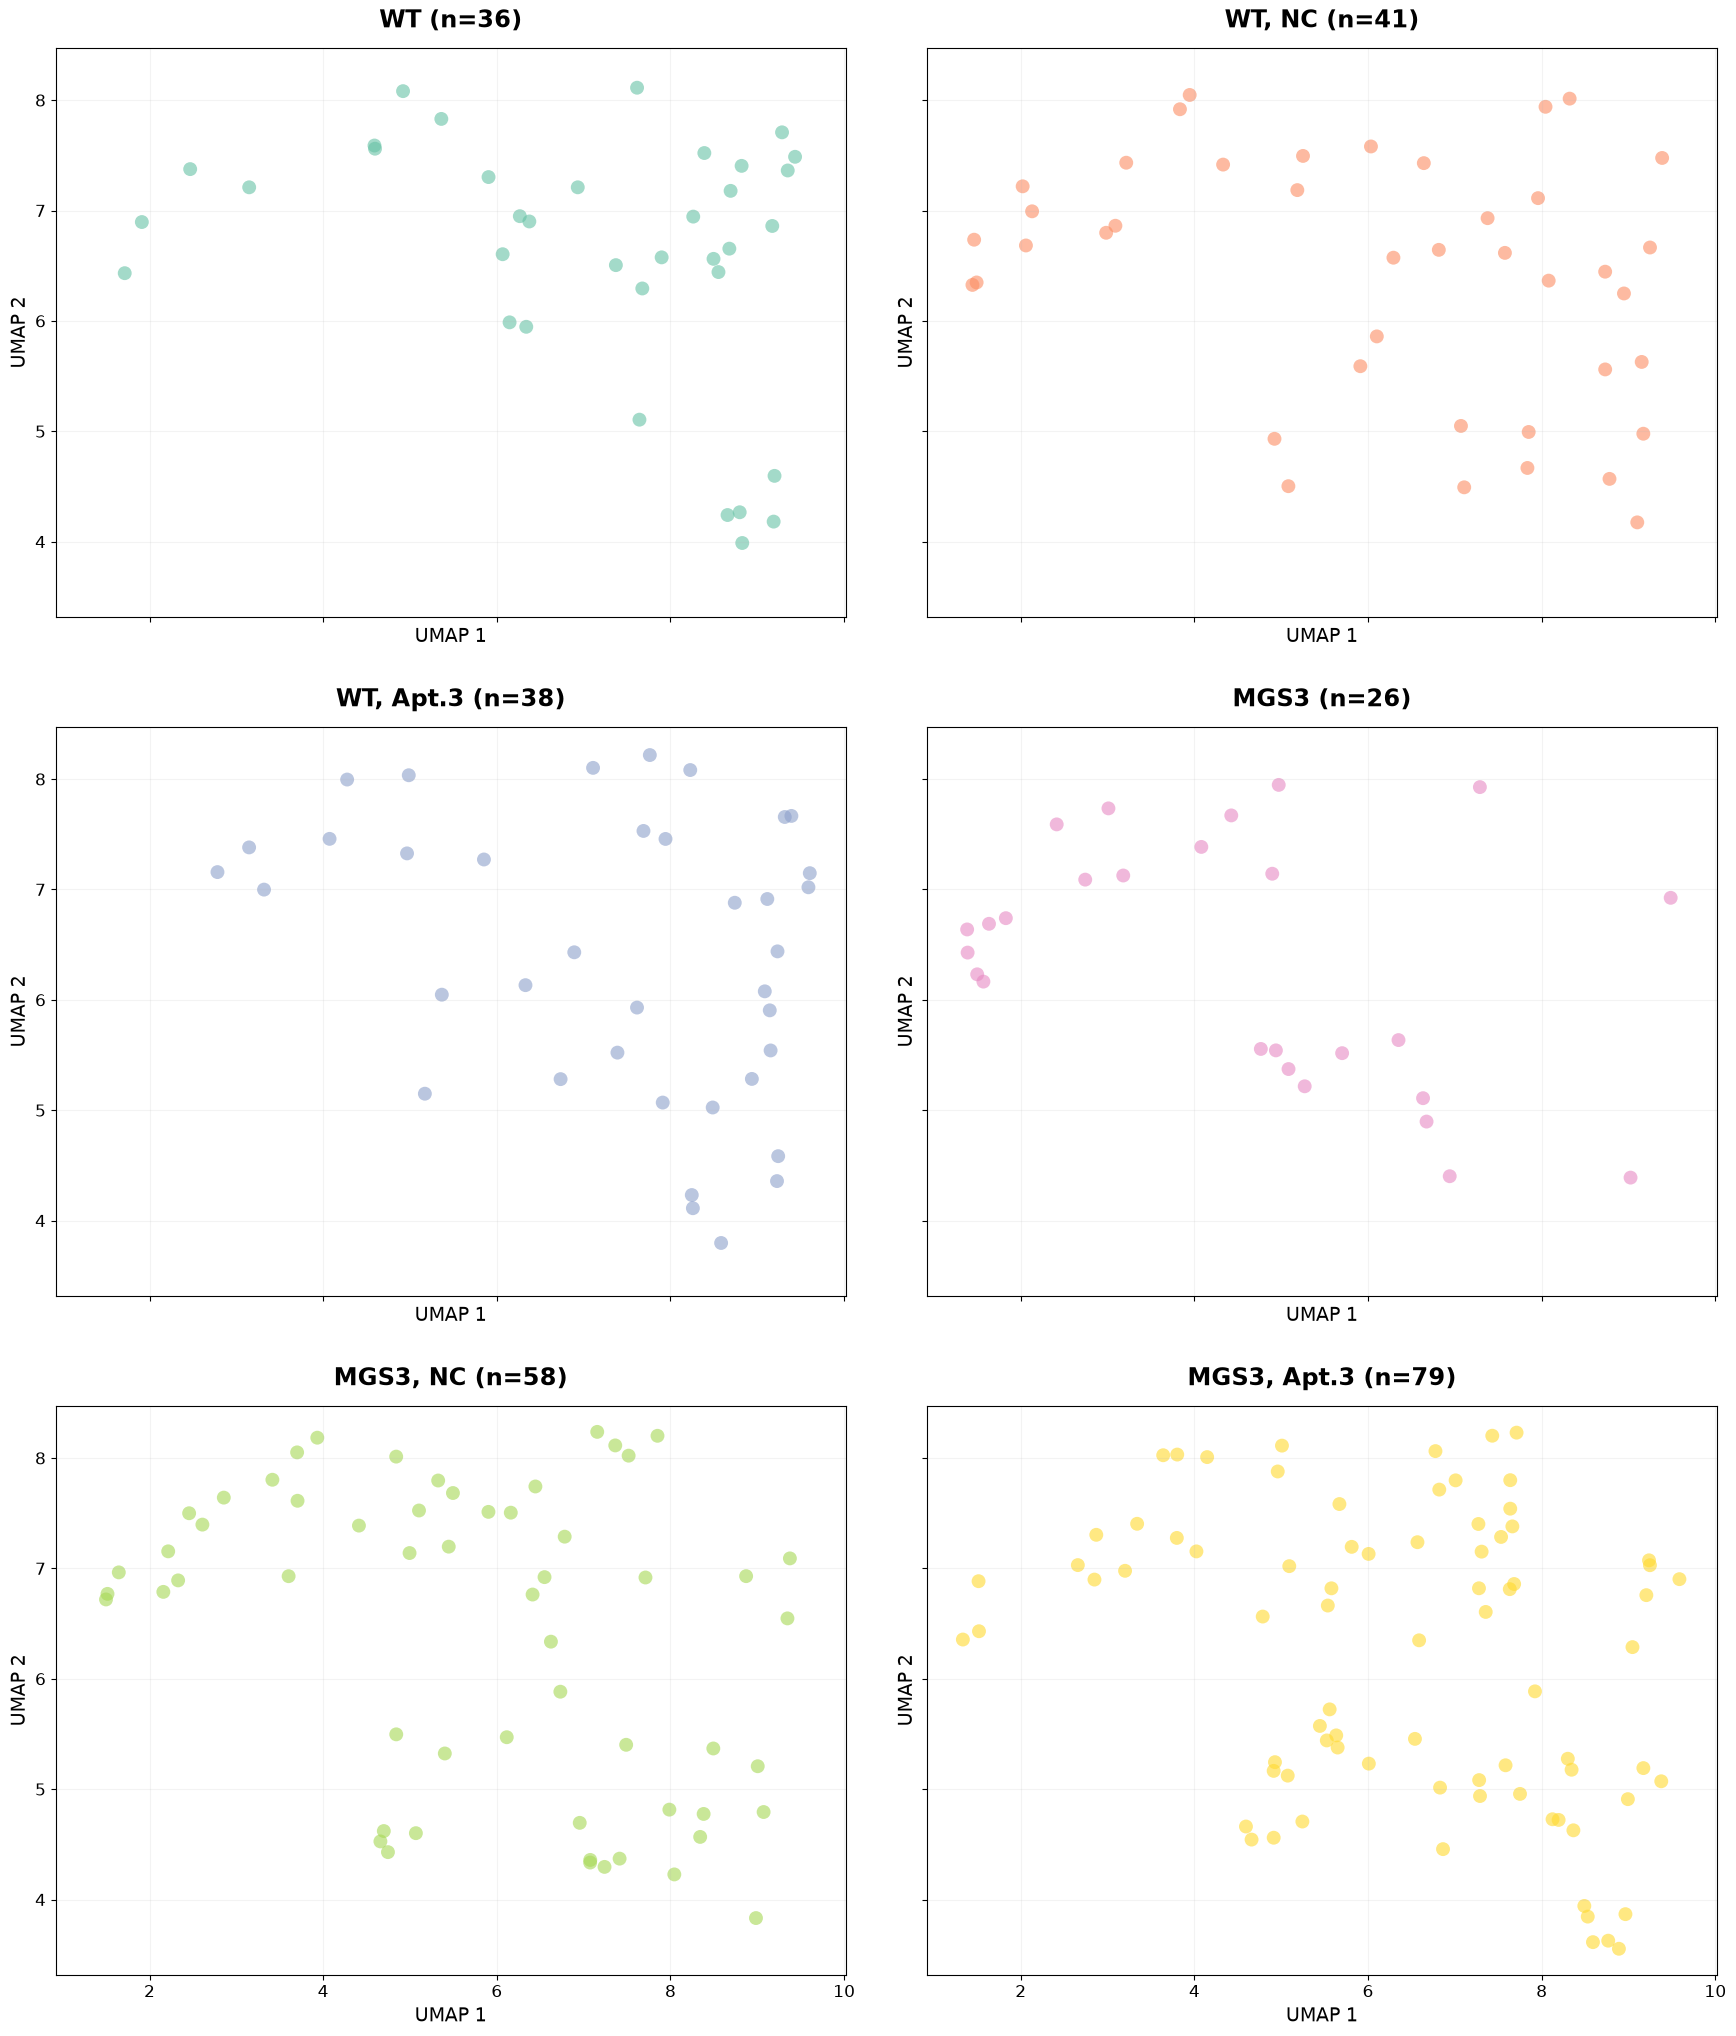

In [11]:
groups = umap_df["sample"].dropna().unique()
n_groups = len(groups)

if n_groups == 0:
    raise ValueError("No samples available for plotting.")

# 3. Layout: 2 columns
ncols = min(2, n_groups)
nrows = math.ceil(n_groups / ncols)

# Consistent colors
palette = dict(zip(
    groups,
    sns.color_palette("Set2", n_groups)
))

colors = sns.color_palette("Set2", len(groups))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(9 * ncols, 7 * nrows),
    sharex=True,
    sharey=True,
    squeeze=False
)

axes = axes.flatten()

# 4. Consistent axis limits
x_min, x_max = umap_df["UMAP1"].min(), umap_df["UMAP1"].max()
y_min, y_max = umap_df["UMAP2"].min(), umap_df["UMAP2"].max()

x_pad = max((x_max - x_min) * 0.05, 0.1)
y_pad = max((y_max - y_min) * 0.05, 0.1)

# 5. Plot each sample
for ax, group, color in zip(axes, groups, colors):

    sample_df = umap_df[umap_df["sample"] == group]

    ax.scatter(
        sample_df["UMAP1"].to_numpy(),
        sample_df["UMAP2"].to_numpy(),
        s=100,
        alpha=0.6,
        color=color,
        edgecolors="none",
        rasterized=True
    )


    ax.set_title(
        f"{group} (n={len(sample_df)})",
        fontsize=17,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("UMAP 1", fontsize=14)
    ax.set_ylabel("UMAP 2", fontsize=14)

    ax.set_xlim(x_min - x_pad, x_max + x_pad)
    ax.set_ylim(y_min - y_pad, y_max + y_pad)

    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.15)

# 6. Remove unused panels
for ax in axes[n_groups:]:
    ax.remove()

plt.tight_layout(pad=3)
plt.show()

# Cluster analysis - 2 stratagies

In [15]:
n_clusters = 3

### KMeans

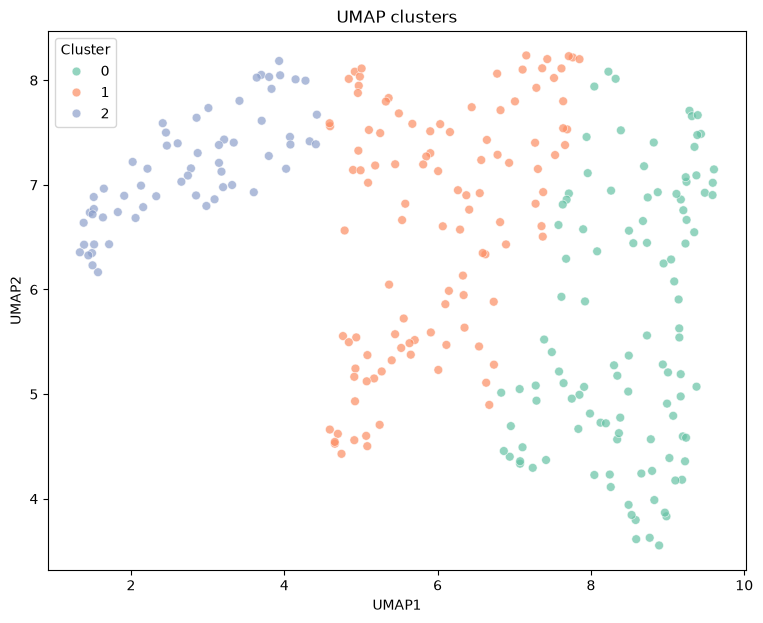

In [18]:
kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=42,
    n_init=100
)

umap_df["cluster"] = kmeans.fit_predict(
    umap_df[["UMAP1", "UMAP2"]]
)

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="Set2",
    s=40,
    alpha=0.7
)

plt.title("UMAP clusters")
plt.legend(title="Cluster")
plt.show()

### AgglomerativeClustering

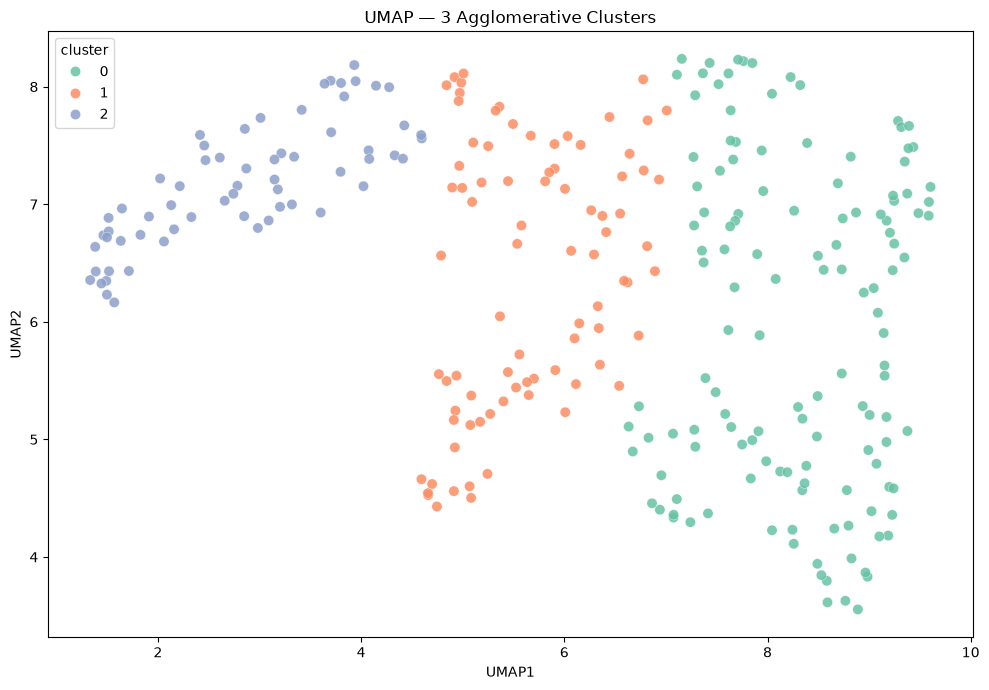

In [17]:
# Cluster UMAP coordinates
X_umap = umap_df[["UMAP1", "UMAP2"]].to_numpy()

clustering = AgglomerativeClustering(
    n_clusters=n_clusters,
    linkage="ward"
)

umap_df["cluster"] = clustering.fit_predict(X_umap)

# Plot clusters
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="Set2",
    s=55,
    alpha=0.85,
    edgecolor="white",
    linewidth=0.3
)

plt.title("UMAP — 3 Agglomerative Clusters")
plt.tight_layout()
plt.show()

## PERMANOVA for all clusters together

In [ ]:
results = run_permanova_permdisp(
    df=umap_df,
    features=features,
    variable="sample"
)   

     Test        F  p_value       R2   n  groups
PERMANOVA 2.873106   0.0005 0.050165 278       6
 PERMDISP 1.832266   0.1055      NaN 278       6


## Cluster visualization separately for all samples

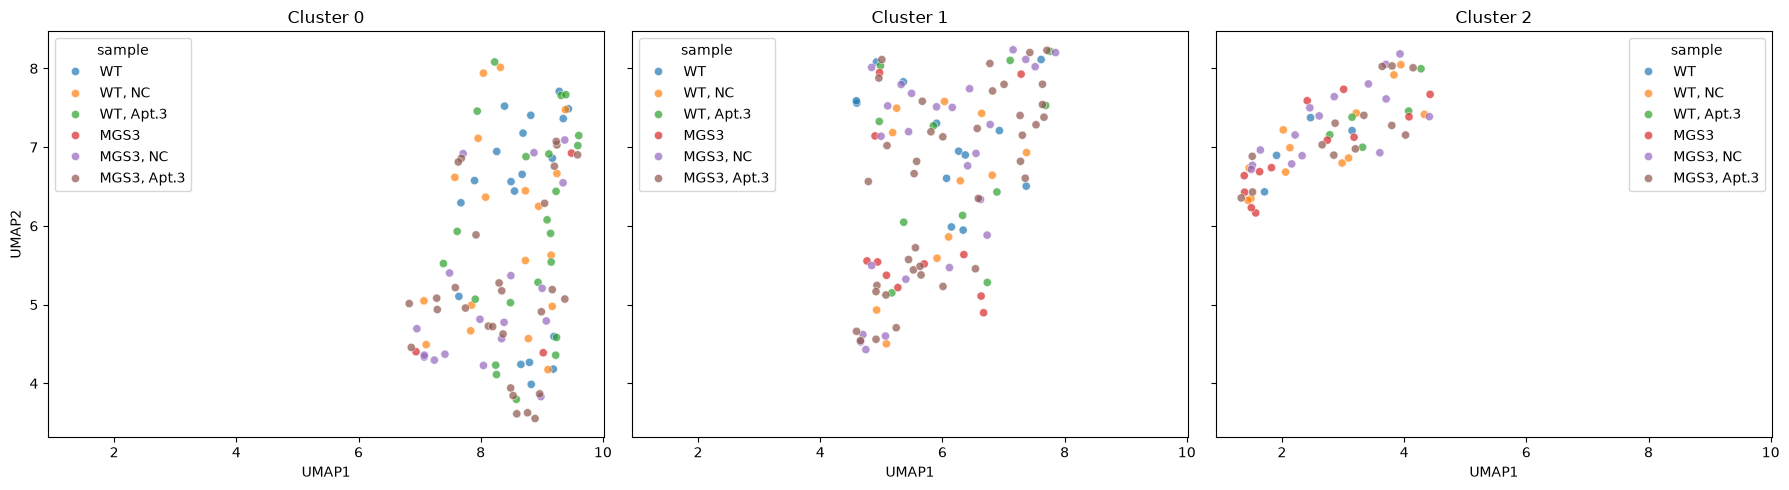

In [22]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 5),
    sharex=True,
    sharey=True
)

for cluster, ax in zip(sorted(umap_df["cluster"].unique()), axes):

    subset = umap_df[umap_df["cluster"] == cluster]

    sns.scatterplot(
        data=subset,
        x="UMAP1",
        y="UMAP2",
        hue="sample",
        palette="tab10",
        alpha=0.7,
        s=35,
        ax=ax
    )

    ax.set_title(f"Cluster {cluster}")

plt.tight_layout()
plt.show()

## Cells per cluster across all samples

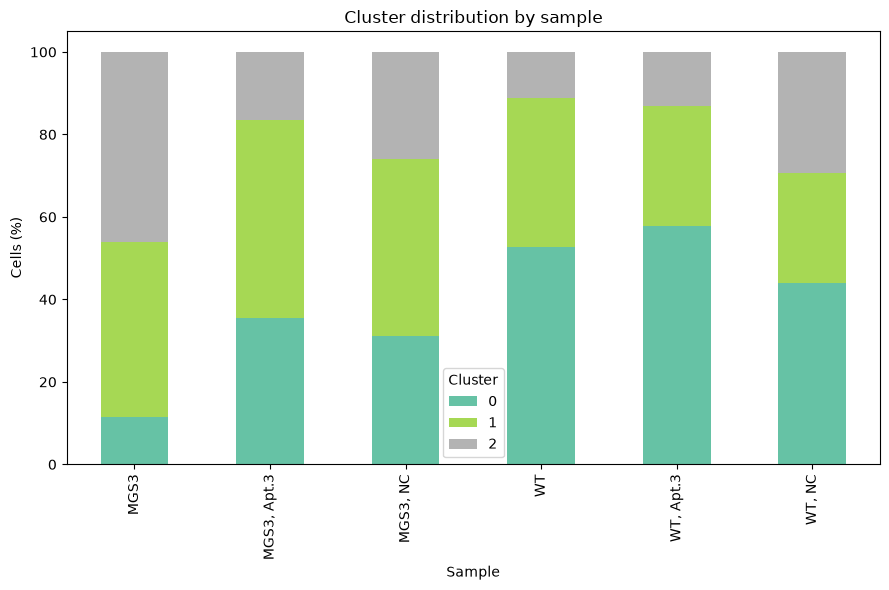

In [23]:
counts = pd.crosstab(
    umap_df["sample"],
    umap_df["cluster"]
)

proportions = counts.div(
    counts.sum(axis=1),
    axis=0
) * 100

#print(proportions.round(2))

proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    colormap="Set2"
)

plt.ylabel("Cells (%)")
plt.xlabel("Sample")
plt.title("Cluster distribution by sample")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# Xi-statistics

In [24]:
# counts is your existing contingency table
display(counts)

# Overall chi-square test
chi2, p, dof, expected = chi2_contingency(counts)

print(f"Chi-square = {chi2:.4f}")
print(f"p-value = {p:.6f}")

# Pairwise comparisons
comparisons = [
    ("WT", "MGS3"),
    ("WT", "WT, NC"),
    ("MGS3", "MGS3, NC"),
    ("WT, NC", "WT, Apt.3"),
    ("MGS3, NC", "MGS3, Apt.3"),
    ("WT, NC", "MGS3, NC"),
    ("WT, Apt.3", "MGS3, Apt.3")
]

results = []

for group1, group2 in comparisons:

    contingency = counts.loc[
        [group1, group2], [0, 1]
    ]

    odds_ratio, p_value = fisher_exact(contingency)

    results.append({
        "comparison": f"{group1} vs {group2}",
        "odds_ratio": odds_ratio,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="fdr_bh" # Benjamini–Hochberg
)[1]

display(results_df)

cluster,0,1,2
sample,,,
MGS3,3,11,12
"MGS3, Apt.3",28,38,13
"MGS3, NC",18,25,15
WT,19,13,4
"WT, Apt.3",22,11,5
"WT, NC",18,11,12


Chi-square = 29.0472
p-value = 0.001224


,comparison,odds_ratio,p_value,p_adjusted
0,WT vs MGS3,5.358974,0.025614,0.114289
1,"WT vs WT, NC",0.893162,1.000000,1.000000
2,"MGS3 vs MGS3, NC",0.378788,0.213772,0.374101
3,"WT, NC vs WT, Apt.3",0.818182,0.792890,1.000000
4,"MGS3, NC vs MGS3, Apt.3",0.977143,1.000000,1.000000
5,"WT, NC vs MGS3, NC",2.272727,0.148839,0.347291
6,"WT, Apt.3 vs MGS3, Apt.3",2.714286,0.032654,0.114289


In [28]:
result

,Test,F,p_value,R2,n,groups
0,PERMANOVA,2.223236,0.0055,0.098272,108,6
1,PERMDISP,1.570435,0.1687,NaN,108,6


## PERMANOVA within each cluster for all samples

In [ ]:
results = []

for cluster, subset in umap_df.groupby("cluster"):

    subset = subset.dropna(subset=features)

    if subset["sample"].nunique() < 2:
        continue
    
    result = run_permanova_permdisp(
    df=subset,
    features=features,
    variable="sample"
    )

    results.append({
        "cluster": cluster,
        "F": result.iloc[0]["F"],
        "p_value": result.iloc[0]["p_value"],
        "R2": result.iloc[0]["R2"],
        "n": len(subset)
    })

results_df = pd.DataFrame(results)

     Test        F  p_value       R2   n  groups
PERMANOVA 2.223236   0.0055 0.098272 108       6
 PERMDISP 1.570435   0.1687      NaN 108       6
     Test        F  p_value       R2   n  groups
PERMANOVA 1.863507   0.0212 0.082957 109       6
 PERMDISP 1.546086   0.1716      NaN 109       6
     Test        F  p_value       R2  n  groups
PERMANOVA 0.934797   0.5306 0.078325 61       6
 PERMDISP 0.995926   0.4144      NaN 61       6
   cluster         F  p_value        R2    n
0        0  2.223236   0.0055  0.098272  108
1        1  1.863507   0.0212  0.082957  109
2        2  0.934797   0.5306  0.078325   61


In [42]:
results_df

,cluster,F,p_value,R2,n
0,0,2.223236,0.0055,0.098272,108
1,1,1.863507,0.0212,0.082957,109
2,2,0.934797,0.5306,0.078325,61


## Check images withon each cluster

In [ ]:
cluster = 0

for i in umap_df.loc[umap_df['cluster'] == cluster, 'image_id']:
    print(i)

### 95% CI UMAP graph

In [ ]:
centroid_df = plot_cluster_centroids_ci(
    umap_df,
    cluster_col="cluster",
    group_col="sample",
    features=("UMAP1", "UMAP2"),
    n_boot=5000,
    confidence=0.95,
    figsize=(14, 11),
    point_size=55,
    centroid_size=300,
    zoom_padding=0.15,
    show_points=True
)

print(centroid_df)

### Centroid distance visualization for each cluster separately

In [ ]:
# Settings
reference = "WT"
group_col = "sample"
cluster_col = "cluster"

# Keep only valid rows
df = umap_df.dropna(
    subset=features + [group_col, cluster_col]
).copy()

# Standardize features globally
# This makes distances comparable between clusters
scaler = StandardScaler()
df[features] = scaler.fit_transform(df[features])

# Consistent colors for mutants
groups = sorted(df[group_col].unique())

palette = dict(zip(
    groups,
    sns.color_palette("Set2", len(groups))
))

# Calculate centroid distances
distance_results = []

for cluster, subset in df.groupby(cluster_col):

    if reference not in subset[group_col].values:
        continue

    # Centroid of each sample
    centroids = subset.groupby(group_col)[features].mean()

    # WT centroid
    ref_centroid = centroids.loc[reference].values

    for group in centroids.index:

        if group == reference:
            continue

        distance = np.linalg.norm(
            centroids.loc[group].values - ref_centroid
        )

        distance_results.append({
            "cluster": cluster,
            "sample": group,
            "distance": distance,
            "n": (subset[group_col] == group).sum()
        })

distance_df = pd.DataFrame(distance_results)

print(distance_df)

# Plot centroid distance trees
clusters = sorted(distance_df["cluster"].unique())

ncols = min(2, len(clusters))
nrows = math.ceil(len(clusters) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(9 * ncols, 6 * nrows),
    squeeze=False
)

axes = axes.flatten()

max_distance = distance_df["distance"].max()

for ax, cluster in zip(axes, clusters):

    data = distance_df[
        distance_df["cluster"] == cluster
    ].sort_values("distance")

    y_positions = np.arange(len(data))

    for y, (_, row) in zip(y_positions, data.iterrows()):

        group = row["sample"]
        distance = row["distance"]

        # Line from WT to mutant centroid
        ax.plot(
            [0, distance],
            [y, y],
            color=palette[group],
            linewidth=2.5,
            alpha=0.8
        )

        # WT reference
        ax.scatter(
            0, y,
            color="black",
            s=70,
            zorder=3
        )

        # Mutant centroid
        ax.scatter(
            distance, y,
            color=palette[group],
            s=160,
            edgecolor="black",
            linewidth=0.8,
            zorder=4
        )

        # Distance label
        ax.text(
            distance + max_distance * 0.02,
            y,
            f"{distance:.2f}",
            va="center",
            fontsize=12
        )

    ax.set_yticks(y_positions)
    ax.set_yticklabels(
        data["sample"],
        fontsize=13
    )

    ax.set_xlim(
        -max_distance * 0.05,
        max_distance * 1.20
    )

    ax.set_xlabel(
        "Euclidean distance from WT centroid",
        fontsize=13
    )

    ax.set_title(
        f"Cluster {cluster}",
        fontsize=17,
        fontweight="bold"
    )

    ax.grid(
        axis="x",
        alpha=0.2
    )

    ax.spines[["top", "right"]].set_visible(False)

# Remove empty subplots
for ax in axes[len(clusters):]:
    ax.remove()

plt.tight_layout(pad=3)
plt.show()

## Difference between clusters

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from sklearn.preprocessing import StandardScaler


# Keep only the two clusters
clusters = sorted(umap_df["cluster"].dropna().unique())

assert len(clusters) == 3, "Expected exactly three clusters"

df_analysis = umap_df.dropna(
    subset=["cluster"] + features
).copy()

# Summary statistics
summary = df_analysis.groupby("cluster")[features].agg(
    ["median", "std", "count"]
)

#display(summary.round(3))

results = []

c0, c1 = clusters

for feature in features:

    x = df_analysis.loc[
        df_analysis["cluster"] == c0, feature
    ].dropna()

    y = df_analysis.loc[
        df_analysis["cluster"] == c1, feature
    ].dropna()

    # Cohen's d
    pooled_sd = np.sqrt(
        ((len(x)-1)*x.var(ddof=1) +
         (len(y)-1)*y.var(ddof=1)) /
        (len(x)+len(y)-2)
    )

    d = (
        (y.median() - x.median()) / pooled_sd
        if pooled_sd > 0 else np.nan
    )

    # Mann–Whitney U
    stat, p = mannwhitneyu(
        x, y,
        alternative="two-sided"
    )

    results.append({
        "feature": feature,
        f"mean_cluster_{c0}": x.mean(),
        f"mean_cluster_{c1}": y.mean(),
        "cohens_d": d,
        "abs_effect_size": abs(d),
        "p_value": p
    })

results_df = pd.DataFrame(results)

# Multiple-testing correction
results_df["p_adjusted"] = multipletests(
    results_df["p_value"],
    method="fdr_bh"
)[1]

results_df = results_df.sort_values(
    "abs_effect_size",
    ascending=False
)

display(results_df.round(2))